# [E-MTAB-12862](https://www.ebi.ac.uk/biostudies/arrayexpress/studies/E-MTAB-12862)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2025-03-19
> - Modified: 2025-03-19

# 1. Experimental Design

> Prognostic whole-genome and transcriptome signatures in colorectal cancers
> - Whole genomic and transcriptomic analyses of 1,063 patients with primary colorectal cancer were conducted, originating from a long-term, population-based cohort with several years of follow-up. This cohort also included 120 normal tissue samples.
> - Nunes, L., Li, F., Wu, M. et al. Prognostic genome and transcriptome signatures in colorectal cancers. Nature 633, 137–146 (2024). https://doi.org/10.1038/s41586-024-07769-3.
> - Total RNA-seq
> - DNBSEQ platform, PE100, 30 M reads per sample.
> - GRCh38
> - STAR -> RNA-SeQC

| Sample | Organism | Tissue | Disease | Group | Replicate |
| - | - | - | - | - | - |
| Normal | Homo sapiens | Colorectum | Colorectal cancer | Normal | 120 |
| Tumour | Homo sapiens | Colorectum | Colorectal cancer | Neoplasm | 1063 |

# 2. Preprocessing

In [ ]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(rtracklayer))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/cohort_Hs_colorectalCancers_PRJEB61514"

In [3]:
expr_mat <- file.path(data_dir, "rnaseq", "CRC.SW.mRNA.symbol.count.txt") |>
    # read.table(header = TRUE, sep = "\t", check.names = FALSE) |>
    data.table::fread() |>
    column_to_rownames("SYMBOL") |> 
    as.matrix()

dim(expr_mat)

expr_mat[1:10, 1:6]

[1] 19765  1183

,CRC.SW.U0001.T,CRC.SW.U0002.T,CRC.SW.U0004.T,CRC.SW.U0005.T,CRC.SW.U0006.T,CRC.SW.U0007.T
A1BG,12,3,14,2,2,6
A1CF,1899,2448,2353,789,571,991
A2M,43569,16953,12739,22840,5547,10137
A2ML1,1,3,1,7,3,32
A3GALT2,0,0,0,0,0,0
A4GALT,544,468,254,330,300,141
A4GNT,0,1,2,0,0,0
AAAS,2168,1262,1914,1123,1070,1353
AACS,1529,1464,1694,695,739,739
AADAC,0,2,15,2,21,4


In [ ]:
clinical_info <- file.path(
    data_dir, "Supplementary_Table", "Supplementary_Table_01.xlsx") |>
    readxl::read_excel(skip = 2) |>
    select(
        Patient_ID = `Sample ID`, 
        Tumour = `RNA Tumor Sample Barcode`, 
        Normal = `RNA Normal Sample Barcode`, 
        Sex, Age = `Age at diagnosis`, 
        Primary_Site = `Primary Site Disease`, 
        Grade = `Tumour Grade`, AJCC_Stage = `Tumour Stage`,
        Survival_Days = `Overall survival days`, 
        Vital_Status = `Vital Status`) |>
    pivot_longer(
        cols = c(Tumour, Normal),
        names_to = "Group", values_to = "Barcode") |>
    filter(Barcode != "Not_Applicable") |>
    mutate(across(where(is.character), ~ na_if(.x, "N/A"))) |>
    mutate(
        Sex = as.factor(Sex), Age = as.integer(Age),
        Primary_Site = as.factor(Primary_Site), 
        Group = as.factor(Group), Grade = as.factor(Grade), 
        AJCC_Stage = as.factor(AJCC_Stage), 
        Survival_Days = as.integer(Survival_Days),
        Vital_Status = as.factor(Vital_Status)) |>
    column_to_rownames("Barcode")

In [5]:
setequal(colnames(expr_mat), rownames(clinical_info))

clinical_info <- clinical_info[colnames(expr_mat), ]

head(clinical_info)

[1] TRUE

,Patient,Sex,Age,Site,Grade,Stage,Survival_Days,Survival_Status,Group
,<chr>,<fct>,<int>,<fct>,<fct>,<fct>,<int>,<fct>,<fct>
CRC.SW.U0001.T,U0001,Female,69,Rectum,Low Grade,Stage II,3496,Dead,Tumour
CRC.SW.U0002.T,U0002,Female,82,Colon,Low Grade,Stage III,4858,Alive,Tumour
CRC.SW.U0004.T,U0004,Female,61,Colon,Low Grade,Stage II,4816,Alive,Tumour
CRC.SW.U0005.T,U0005,Female,44,Colon,High Grade,Stage III,2496,Dead,Tumour
CRC.SW.U0006.T,U0006,Male,63,Colon,High Grade,Stage III,799,Dead,Tumour
CRC.SW.U0007.T,U0007,Male,72,Colon,Low Grade,Stage III,4690,Alive,Tumour


In [6]:
# exon_info <- "~/reference/Homo_sapiens/hg38/gencode.v35.basic.annotation.gtf.gz" |>
#     rtracklayer::import(feature.type = "exon")

In [7]:
# gene_info <- split(exon_info, exon_info$gene_id) |> 
#     reduce() |>
#     map_int(\(x) sum(width(x))) |>
#     enframe(name = "gene_id", value = "basepairs") |>
#     left_join(
#         mcols(exon_info) |> as.data.frame() |>
#         select(gene_id, gene_name, gene_type) |>
#         distinct(), by = "gene_id") |>
#     mutate(gene_id = sub("\\..*", "", gene_id)) |>
#     column_to_rownames("gene_id") |>
#     DataFrame()

In [8]:
eSet <- SummarizedExperiment(
    assays = list(counts = expr_mat), 
    colData = clinical_info)

eSet

class: SummarizedExperiment 
dim: 19765 1183 
metadata(0):
assays(1): counts
rownames(19765): A1BG A1CF ... ZZEF1 AC118549.1
rowData names(0):
colnames(1183): CRC.SW.U0001.T CRC.SW.U0002.T ... CRC.SW.UM172.T
  CRC.SW.UM173.T
colData names(9): Patient Sex ... Survival_Status Group

In [9]:
dds <- DESeqDataSet(eSet, design = ~ Group)

In [10]:
dgel <- DGEList(
    counts = expr_mat, samples = clinical_info, 
    group = clinical_info$Group)

# 3. Normalization

In [11]:
vsd <- vst(dds, blind = FALSE)

Warning message:
“`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors.”


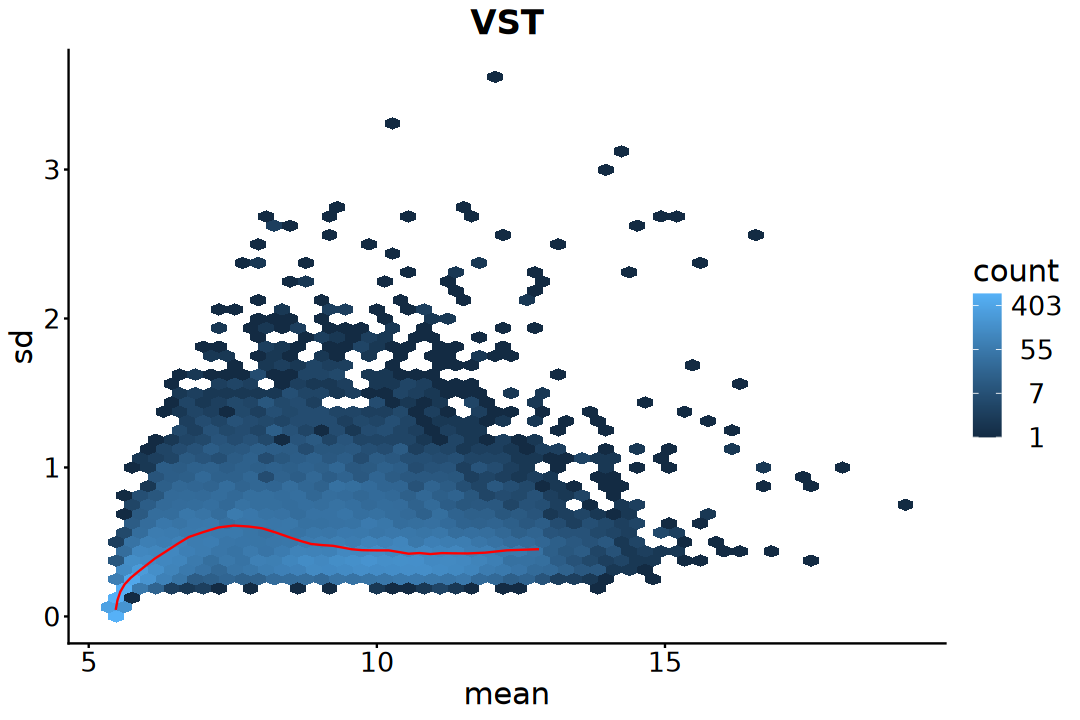

In [12]:
options(repr.plot.width = 9, repr.plot.height = 6)

vsn::meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

# 4. Exploration

In [13]:
norm_mat <- assay(vsd)

## 1). Overview

In [14]:
plot_df <- colData(dds) |> as.data.frame() |>
    rownames_to_column(var = "Sample") |>
    mutate(librarySize = colSums(counts(dds))[Sample])

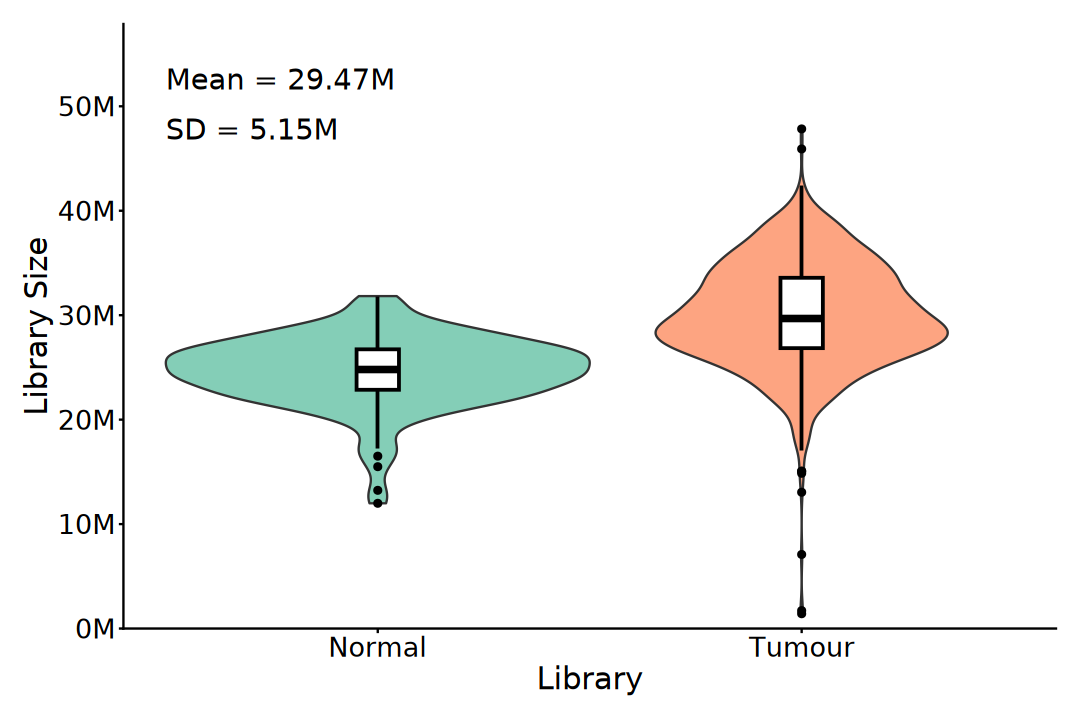

In [15]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Group, y = librarySize)) +
    geom_violin(
        aes(fill = Group), width = 1, alpha = 0.8,
        trim = TRUE, show.legend = FALSE) +
    geom_boxplot(
        color = "black", fill = "white", width = 0.1, 
        linewidth = 0.8, show.legend = FALSE) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("Mean = ", round(mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1,
        label = paste0("SD = ", round(sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"), 
        limits = c(0, NA), expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set2") +
    labs(x = "Library", y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

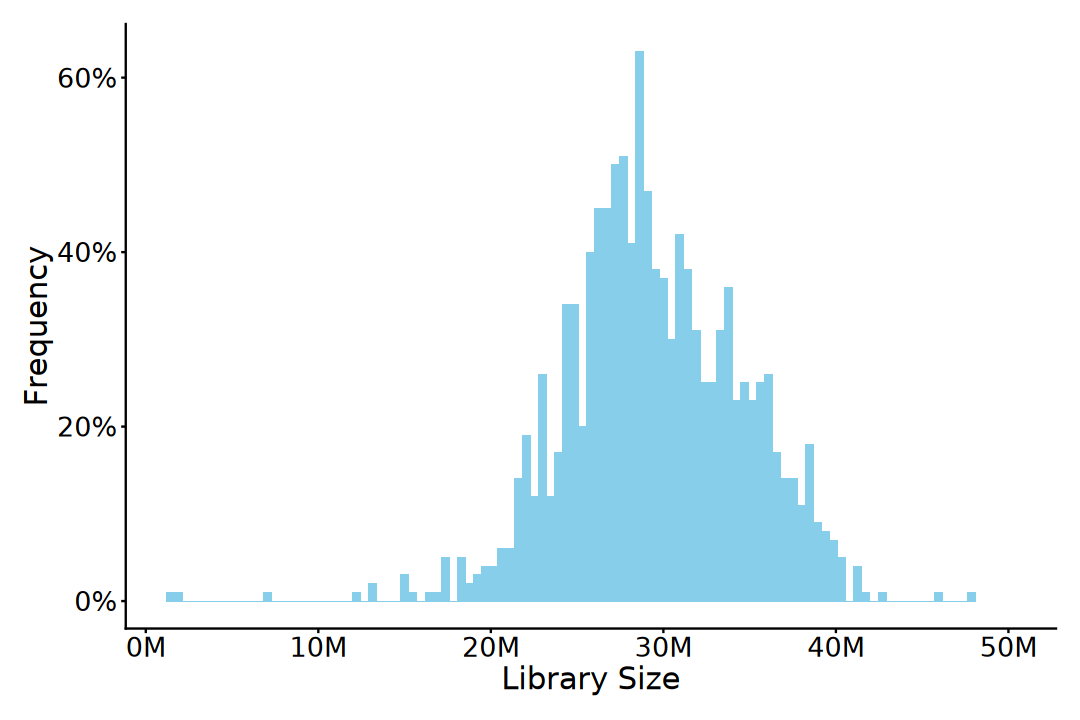

In [16]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = librarySize)) +
    geom_histogram(
        position = "identity", bins = 100, fill = "skyblue") +
    scale_x_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0.05, 0.1))) +
    scale_y_continuous(
        labels = scales::label_percent(scale = 1)) +
    labs(x = "Library Size", y = "Frequency") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 2). PCA

In [17]:
# CV can eliminate the bias that "high abundance tends to have large variance".
top_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> 
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)

In [18]:
pca_res <- norm_mat[top_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(
    pca_res$x[, 1:3], colData(dds)[, c("Group"), drop = FALSE],
    by = "row.names")

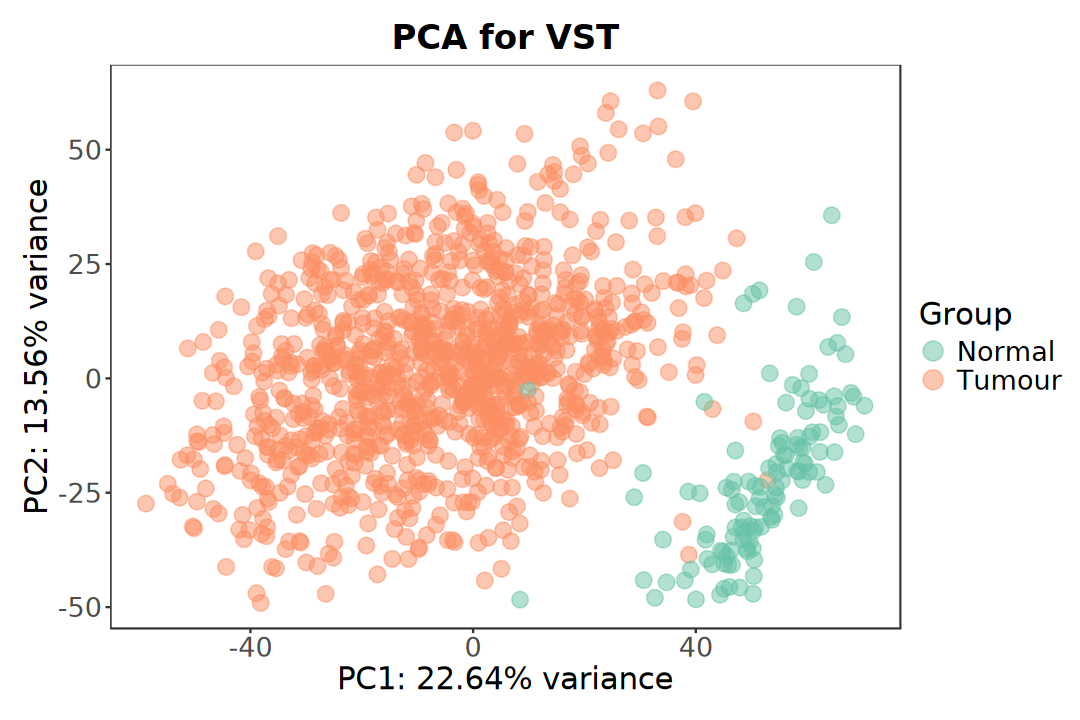

In [19]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(
        aes(color = Group), size = 4, alpha = 0.5) +
    scale_color_brewer(palette = "Set2") +
    labs(
        title = "PCA for VST", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 3). Heatmap

In [20]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Sex, Site, Stage, Group)

In [ ]:
sex_colors <- setNames(
    scales::brewer_pal(palette = "Paired")(nlevels(dds$Sex)),
    levels(dds$Sex))
site_colors <- setNames(
    scales::brewer_pal(palette = "Dark2")(nlevels(dds$Primary_Site)),
    levels(dds$Primary_Site))
stage_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$AJCC_Stage)),
    levels(dds$AJCC_Stage))
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))

anno_colors <- list(
    Sex = sex_colors, Primary_Site = site_colors, 
    AJCC_Stage = stage_colors, Group = group_colors)

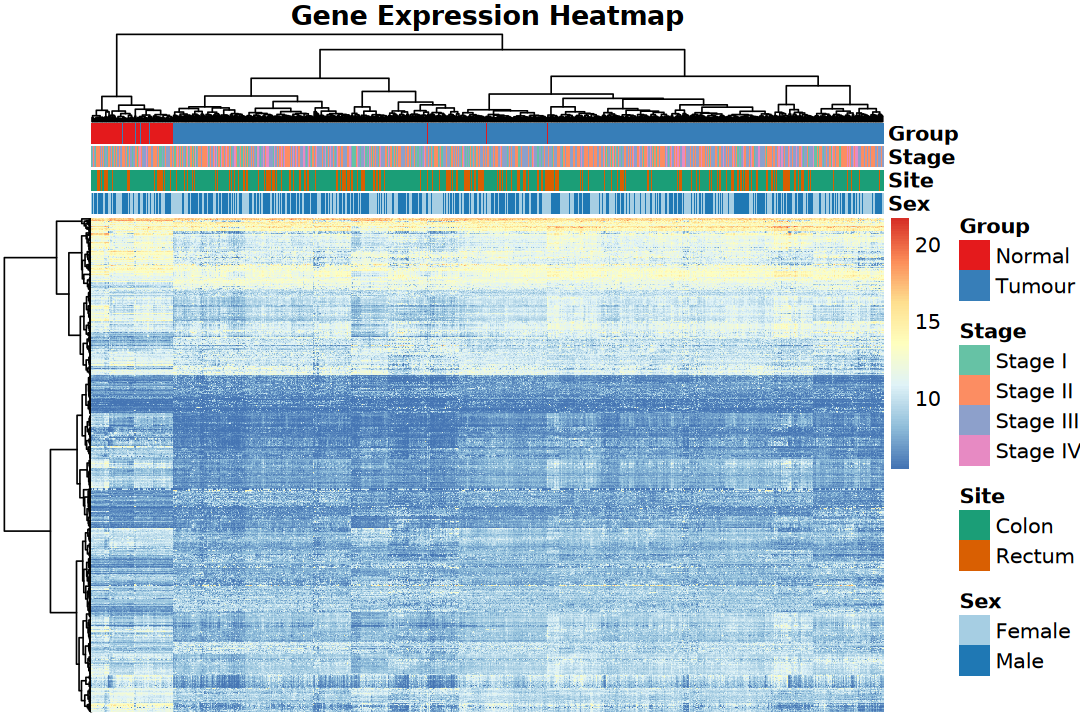

In [22]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    norm_mat[top_idx, ],
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    clustering_distance_rows = "euclidean",
    clustering_method = "ward.D2",
    main = "Gene Expression Heatmap", fontsize = 12, 
    show_colnames = FALSE, show_rownames = FALSE)

## 4). Correlation

In [23]:
cor_mat <- cor(norm_mat[top_idx, ], method = "spearman")

In [24]:
colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

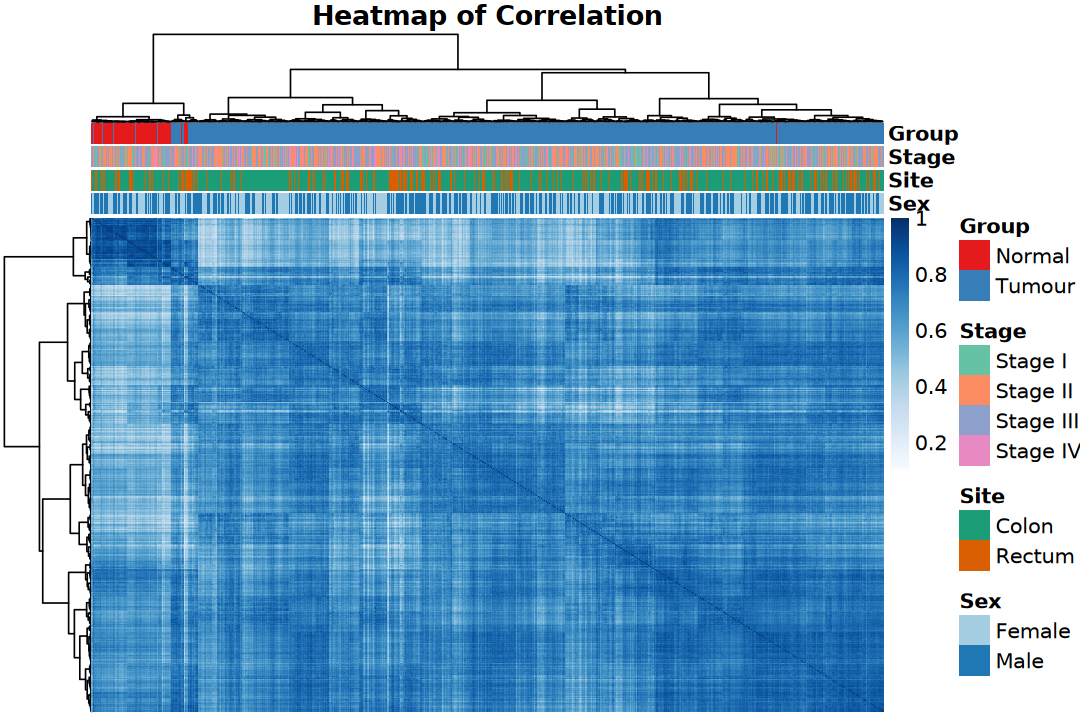

In [25]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    clustering_method = "ward.D2",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 12,
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs Analysis

In [26]:
logfc_cutoff <- log2(4)
p_cutoff <- 0.05

## 1). DESeq2

In [27]:
dds <- DESeq(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing

-- replacing outliers and refitting for 911 genes
-- DESeq argument 'minReplicatesForReplace' = 7 
-- original counts are preserved in counts(dds)

estimating dispersions

fitting model and testing



In [28]:
res <- results(
    dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, name = "Group_Tumour_vs_Normal", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, contrast = c("Group", "Tumour", "Normal"), 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 19438 with nonzero total read count
adjusted p-value < 0.05
LFC > 2.00 (up)    : 387, 2%
LFC < -2.00 (down) : 384, 2%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 0)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [29]:
deseq2_result <- res |> as.data.frame() |> 
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
  387   384 18994 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
A1BG,6.648618,-0.8744138,0.12040225,-7.262437,1.0000000,1,NS
A1CF,1640.419593,-0.9975569,0.09969661,-10.005926,1.0000000,1,NS
A2M,18373.096598,-0.9699311,0.08073875,-12.013203,1.0000000,1,NS
A2ML1,11.725662,1.7712983,0.25074418,7.064165,0.8191398,1,NS
A3GALT2,0.621115,-0.6975952,0.28193929,-2.474274,0.9999981,1,NS
A4GALT,370.036920,-0.6527388,0.09045765,-7.215960,1.0000000,1,NS


In [30]:
res_lfc <- lfcShrink(
    dds, coef = "Group_Tumour_vs_Normal", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895

Warning message in nbinomGLM(x = x, Y = YNZ, size = size, weights = weightsNZ, offset = offsetNZ, :
“the line search routine failed, unable to sufficiently decrease the function value”



out of 19438 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 7275, 37%
LFC < 0 (down)     : 8618, 44%
outliers [1]       : 0, 0%
low counts [2]     : 0, 0%
(mean count < 0)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [31]:
deseq2_result <- res_lfc |> as.data.frame() |> 
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
  652   748 18365 

,baseMean,logFC,lfcSE,pvalue,padj,result
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
A1BG,6.648618,-0.8613964,0.11994663,3.801769e-13,7.816669e-13,NS
A1CF,1640.419593,-0.9866197,0.09934847,1.435421e-23,4.031458e-23,NS
A2M,18373.096598,-0.9482204,0.08012991,3.028822e-33,1.107283e-32,NS
A2ML1,11.725662,3.1566827,0.25358522,1.615848e-12,3.262241e-12,Up
A3GALT2,0.621115,-0.6212589,0.27456566,1.335071e-02,1.739817e-02,NS
A4GALT,370.036920,-0.6459831,0.09006304,5.355468e-13,1.096478e-12,NS


## 2). edgeR

In [32]:
design <- model.matrix(~ group, data = dgel$samples)

In [33]:
dgel <- estimateDisp(dgel, design)

In [34]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [35]:
edger_result <- topTags(qlf, n = Inf) |> as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_result$result)
head(edger_result)


   Up  Down    NS 
  807   577 18381 

,logFC,logCPM,F,pvalue,padj,result
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
OTOP2,-6.586202,2.962685,3249.618,0.000000e+00,0.000000e+00,Down
G6PC,-5.511930,-1.244030,2178.815,0.000000e+00,0.000000e+00,Down
BEST4,-5.190721,2.782096,3246.315,0.000000e+00,0.000000e+00,Down
DAO,-4.395214,-1.145779,2193.776,0.000000e+00,0.000000e+00,Down
CA7,-5.292268,3.124765,2788.250,8.204306e-312,3.243162e-308,Down
GUCA2B,-5.379683,2.404778,2381.702,1.166267e-283,3.841876e-280,Down


## 3). limma-voom

In [36]:
design <- model.matrix(~ group, data = dgel$samples)

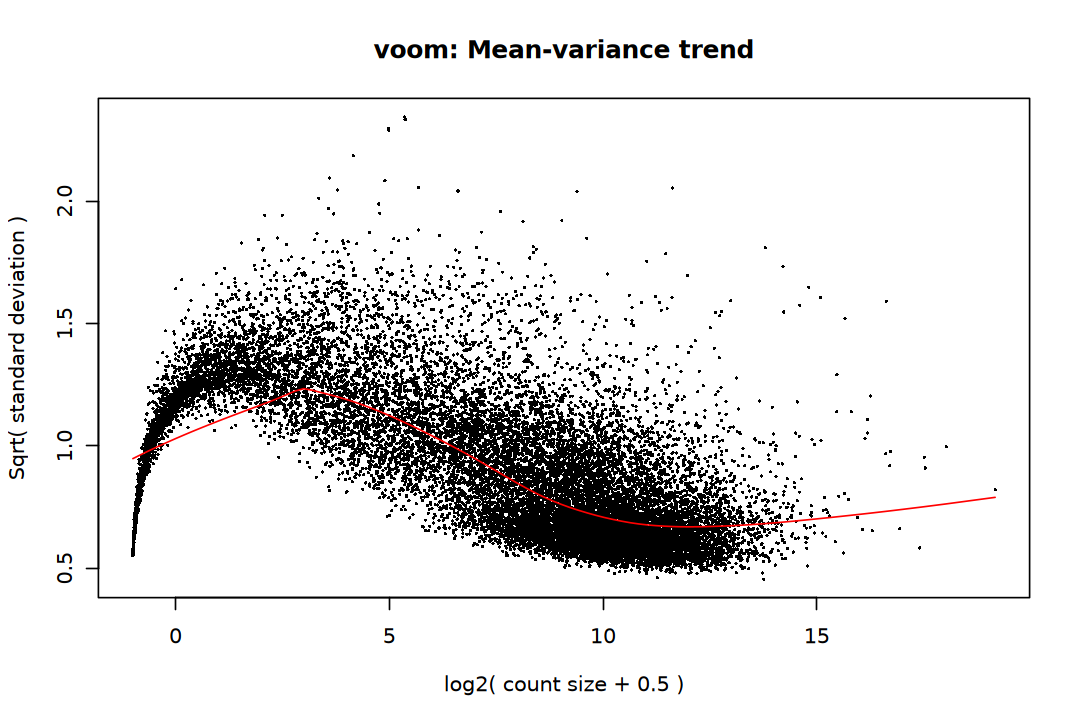

In [37]:
options(repr.plot.width = 9, repr.plot.height = 6)

v <- voom(dgel, design, plot = TRUE)

In [38]:
# Linear Model for Series of Arrays
fit <- lmFit(v, design)
# Empirical Bayes Statistics for Differential Expression
fit <- eBayes(fit)

In [39]:
limma_result <- topTable(fit, coef = 2, number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_result$result)
head(limma_result)


   Up  Down    NS 
  371   831 18563 

,logFC,AveExpr,t,pvalue,padj,B,result
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
BEST4,-5.709449,0.2203227,-71.02815,0.000000e+00,0.000000e+00,973.1881,Down
OTOP2,-8.701080,-2.2867478,-66.30690,0.000000e+00,0.000000e+00,908.4574,Down
CA7,-6.199454,0.2120057,-66.16005,0.000000e+00,0.000000e+00,906.4098,Down
GUCA2B,-6.938582,-1.3545458,-54.15942,9.881313e-323,4.882604e-319,728.7434,Down
SLC25A34,-3.517910,1.0203290,-48.41285,5.343726e-283,2.112375e-279,637.5835,Down
SPIB,-4.557596,0.6663006,-47.64716,1.406697e-277,4.633896e-274,625.2098,Down


## 4). Wilcoxon-test

In [40]:
# # TPM
# norm_mat <- assays(eSet)$TPM

# # DESeq2 normalization
# norm_mat <- counts(dds, normalized = TRUE)

# edgeR TMM
norm_mat <- cpm(
    dgel, normalized.lib.sizes = TRUE, 
    log = TRUE, prior.count = 1)

# # voom
# design <- model.matrix(~ group, data = dgel$samples)
# norm_mat <- voom(dgel, design, plot = FALSE)

In [41]:
# =============================================================================
# Wilcoxon-test based Differential Expression Analysis
# =============================================================================
# Cliff's Delta: effect size, range [-1, 1]
#   Formula: delta = (2U)/(m*n) - 1  (equivalent to (U1 - U2) / (m*n))
#   Note: wilcox.test W statistic = U1 (treat vs control)
#         so U = W - m*(m+1)/2 gives U2 (control vs treat)
#         correct formula should use U1: delta = (2*W_U1)/(m*n) - 1
# =============================================================================

wilcoxDEG <- function(mat, group, adjust_method = "BH") {
    idx_c <- which(group == levels(group)[1])
    num_c <- length(idx_c)
    idx_t <- which(group == levels(group)[2])
    num_t <- length(idx_t)
    
    result <- apply(mat, 1, function(x) {
        wt <- wilcox.test(
            x[idx_t], x[idx_c], exact = FALSE, correct = FALSE)
        W <- wt$statistic |> as.numeric()
        c(
            logFC = mean(x[idx_t]) - mean(x[idx_c]),
            W = W,
            cliffs_delta = (2 * W) / (num_t * num_c) - 1,
            pvalue = wt$p.value)
    }) |> t() |> as.data.frame()
    
    result$padj <- p.adjust(result$pvalue, method = adjust_method)
    return(result)
}

In [42]:
res <- wilcoxDEG(norm_mat, group = dgel$samples$group)

In [43]:
wilcox_result <- res |> 
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(wilcox_result$result)
head(wilcox_result)


   Up  Down    NS 
  342   702 18721 

,logFC,W,cliffs_delta,pvalue,padj,result
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
A1BG,-0.7068976,40818.0,-0.36001881,9.493269e-11,1.748853e-10,NS
A1CF,-1.0408222,26499.0,-0.58452493,7.885121e-26,2.364221e-25,NS
A2M,-0.9263947,21886.0,-0.65685168,3.511362e-32,1.297963e-31,NS
A2ML1,0.4512487,69006.0,0.08193791,1.396750e-01,1.669293e-01,NS
A3GALT2,-0.1068609,59843.5,-0.06171997,2.268218e-01,2.648041e-01,NS
A4GALT,-0.5701369,42210.0,-0.33819379,1.201397e-09,2.133862e-09,NS


# 6. DEGs Visualization

## 1). Volcano

In [44]:
add_label <- function(res){
    res |> 
    rownames_to_column("symbol") |>
    group_by(result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            result %in% c("Up", "Down") & row_number() <= 10,
            symbol, NA_character_)) |>
    ungroup() |>
    column_to_rownames("symbol")
}

In [45]:
deseq2_result <- add_label(deseq2_result)
edger_result <- add_label(edger_result)
limma_result <- add_label(limma_result)
wilcox_result <- add_label(wilcox_result)

In [46]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 10) * 10)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), 
            na.rm = TRUE, alpha = 1) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(color = result, label = label), na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [47]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")
p4 <- ggplot_volcano(wilcox_result, title = "Wilcoxon-test")

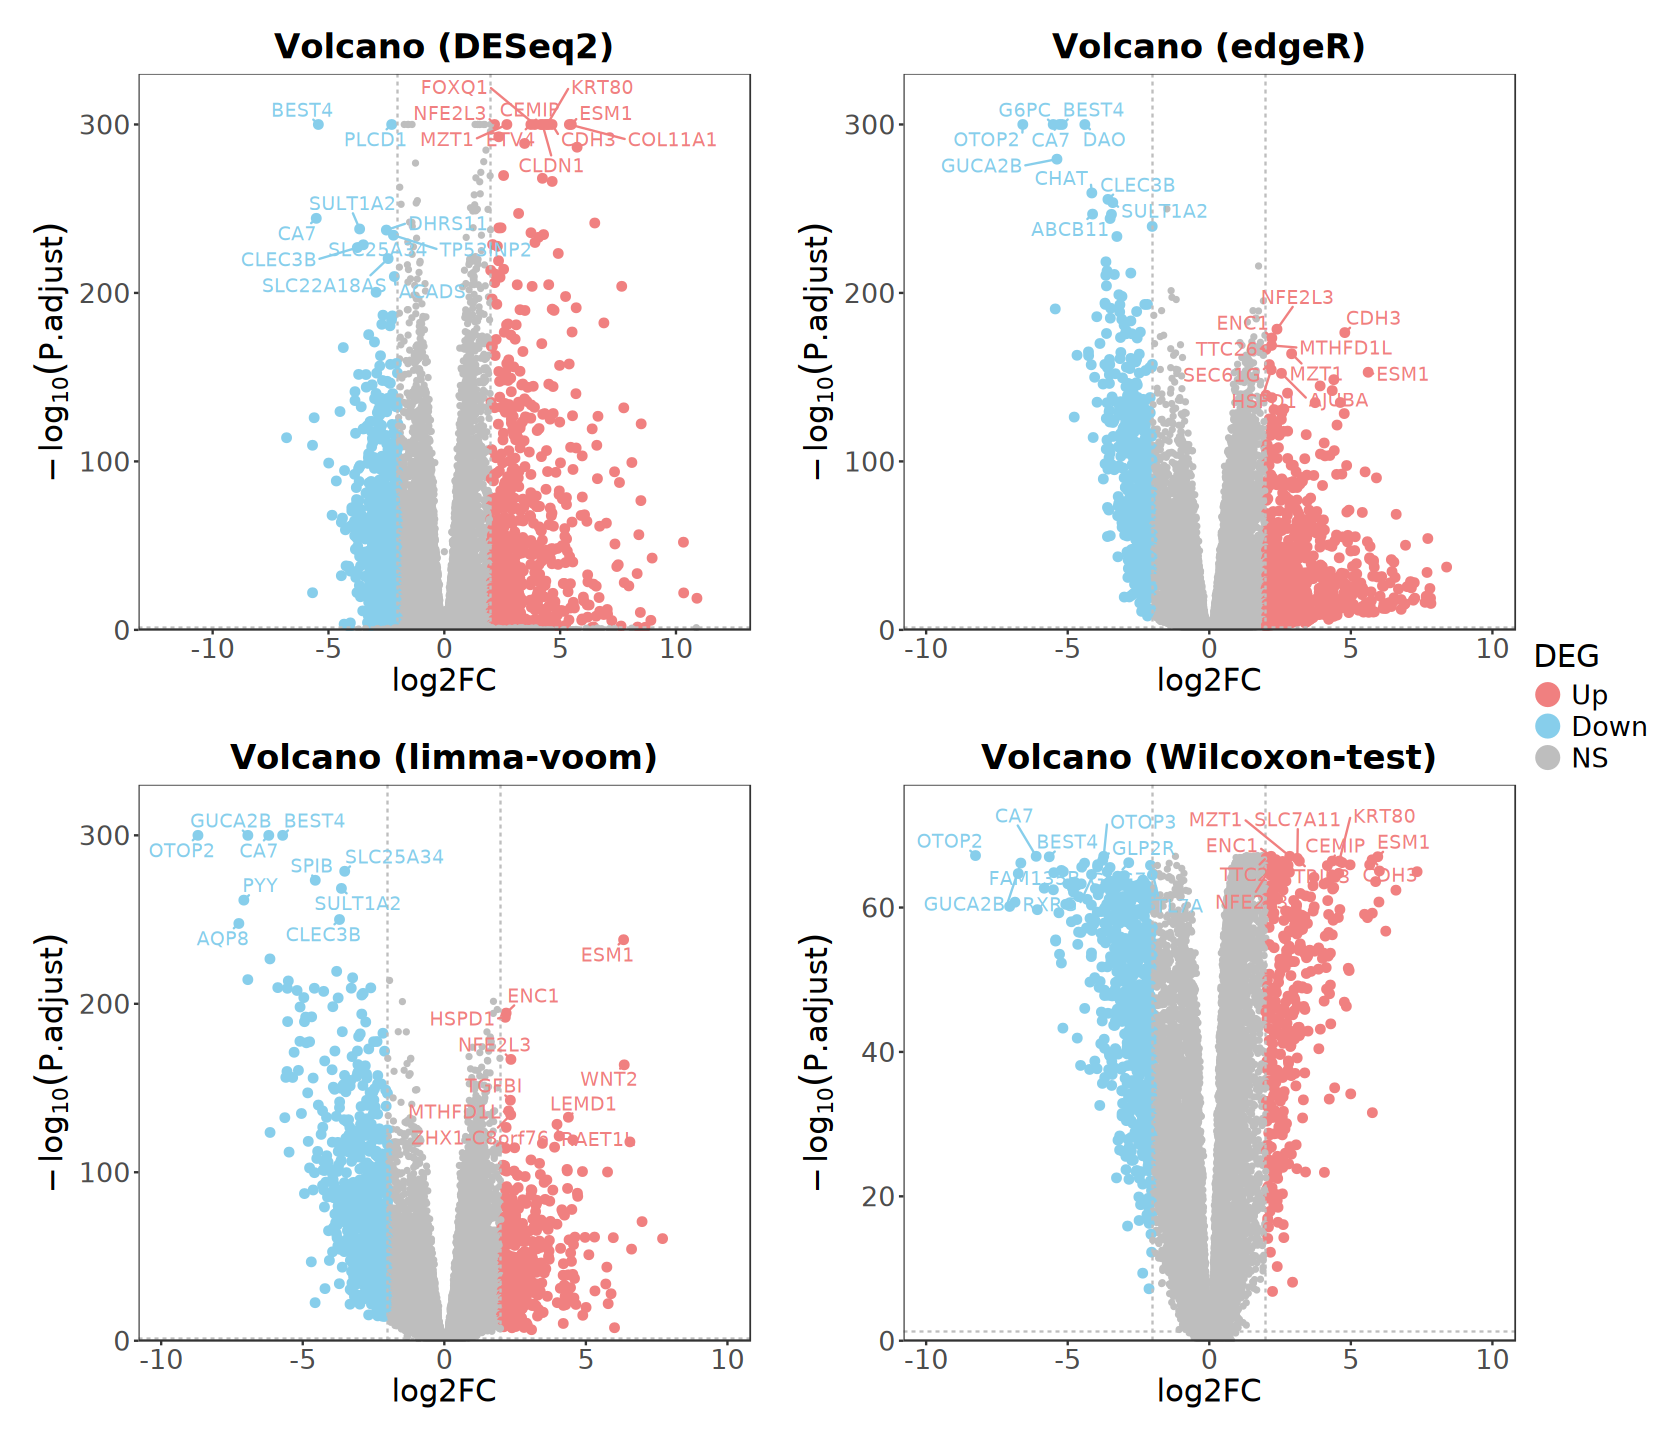

In [48]:
options(repr.plot.width = 14, repr.plot.height = 12)
p1 + p2 + p3 + p4 + plot_layout(nrow = 2, guides = "collect")

## 2). Heatmap

## 3). Venn

In [49]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [50]:
genes_up <- list(
    DESeq2 = rownames(deseq2_result)[deseq2_result$result == "Up"], 
    edgeR = rownames(edger_result)[edger_result$result == "Up"], 
    limma = rownames(limma_result)[limma_result$result == "Up"],
    Wilcox = rownames(wilcox_result)[wilcox_result$result == "Up"])
genes_up <- lapply(genes_up, unique)

In [51]:
genes_down <- list(
    DESeq2 = rownames(deseq2_result)[deseq2_result$result == "Down"], 
    edgeR = rownames(edger_result)[edger_result$result == "Down"], 
    limma = rownames(limma_result)[limma_result$result == "Down"],
    Wilcox = rownames(wilcox_result)[wilcox_result$result == "Down"])
genes_down <- lapply(genes_down, unique)

In [52]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1) +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16))

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1) +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16))

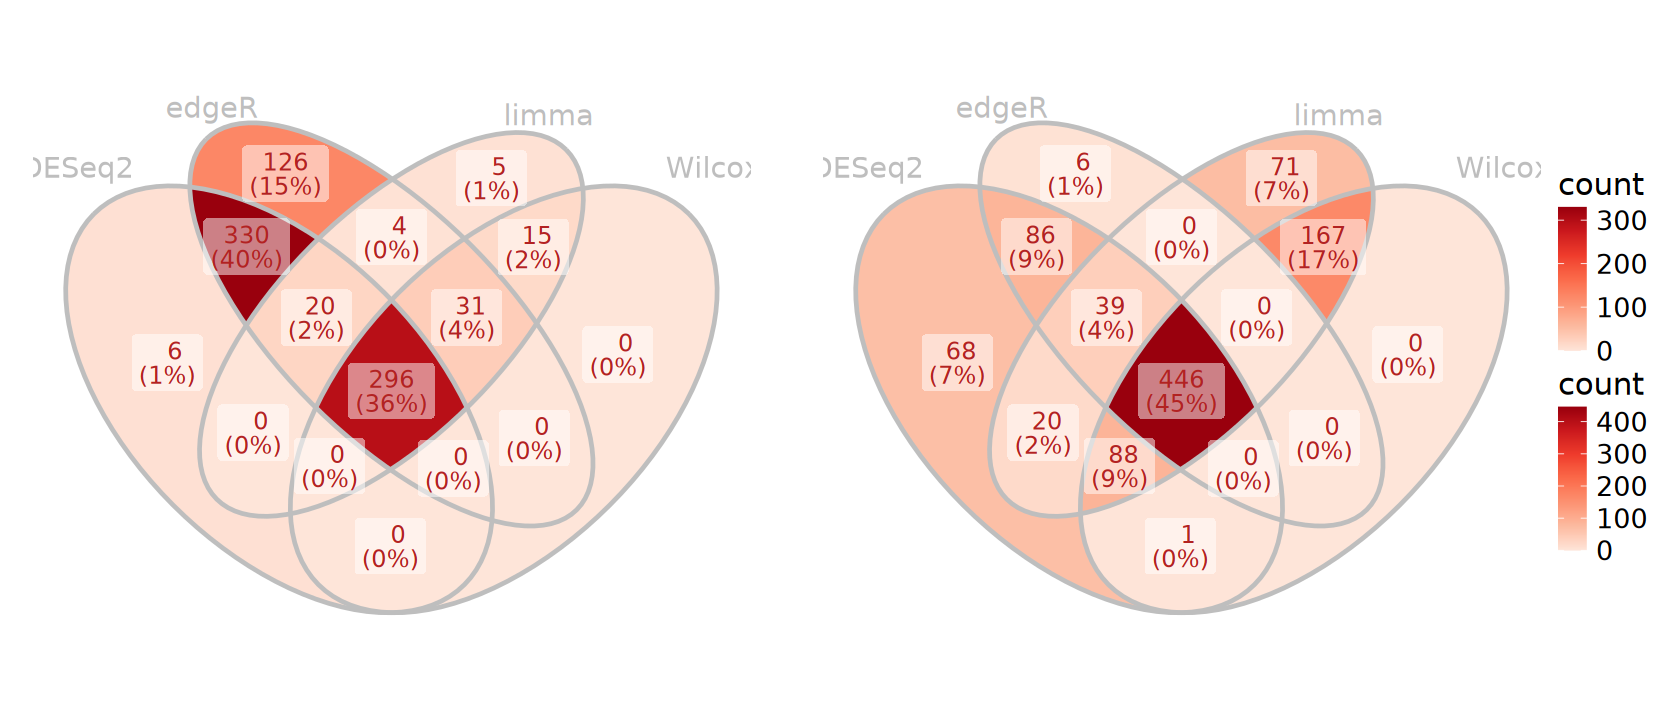

In [53]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 + 
    plot_layout(ncol = 3, widths = c(1, 0.01, 1), guides = "collect")

## 4). Upset

In [54]:
suppressPackageStartupMessages(library(UpSetR))

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors.”


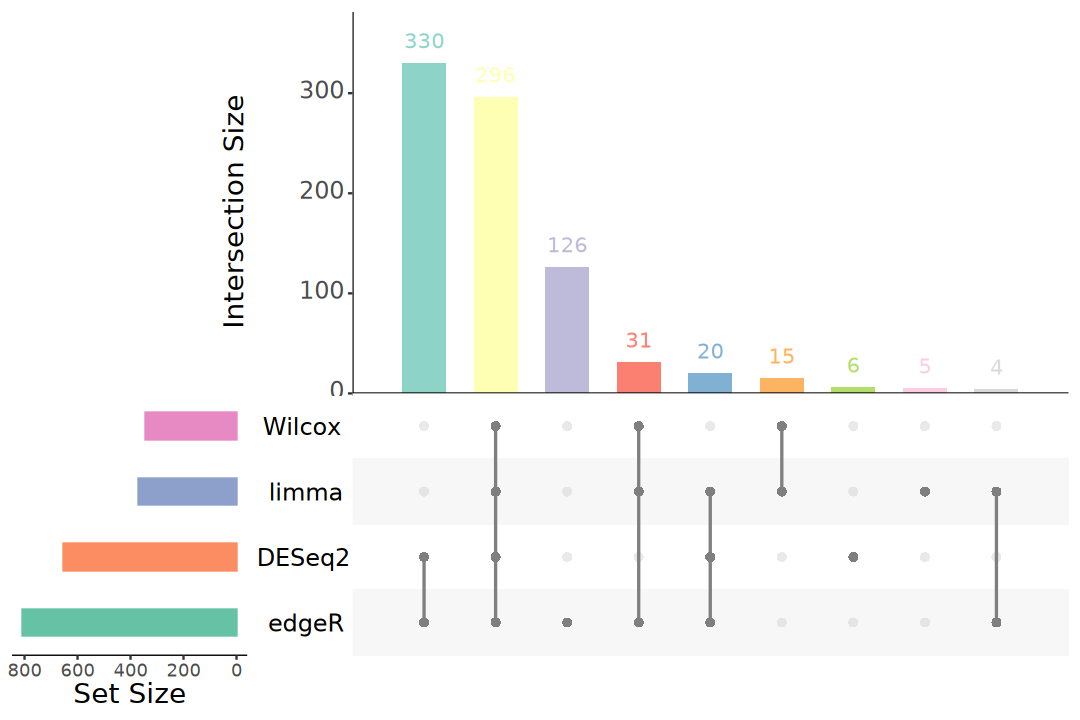

In [55]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 4, name = "Set2"),
    main.bar.color = brewer.pal(n = 9, name = "Set3"),
    matrix.color = "grey50",
    text.scale = c(2, 2, 2, 1.5, 2, 2))

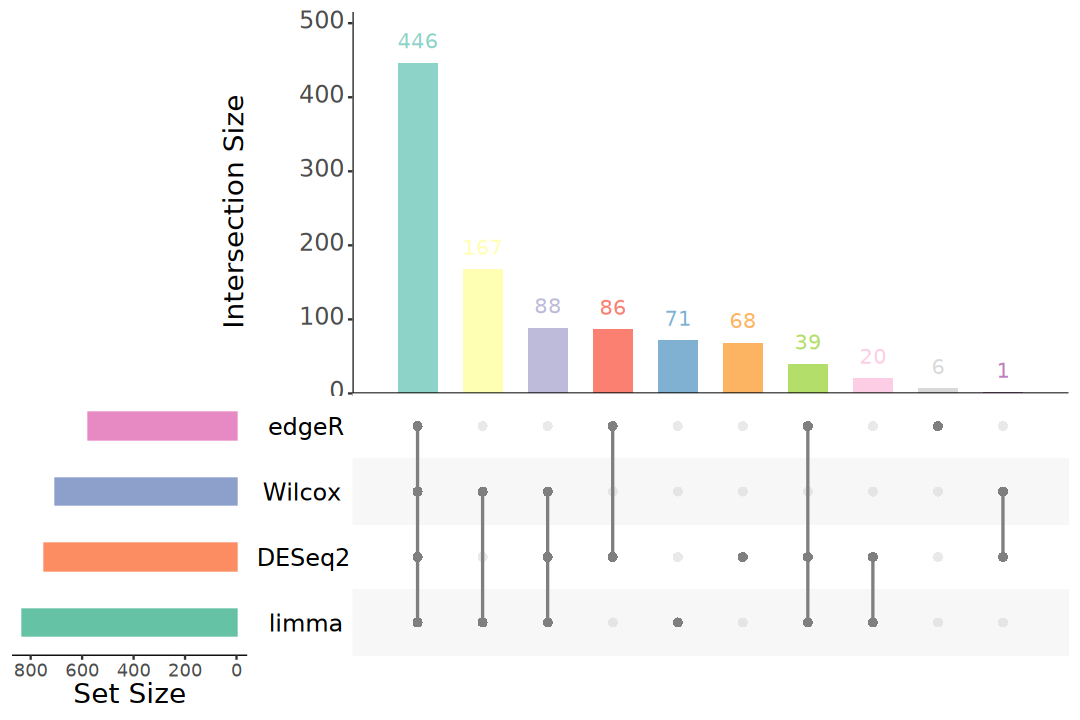

In [56]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 4, name = "Set2"),
    main.bar.color = brewer.pal(n = 10, name = "Set3"),
    matrix.color = "grey50",
    text.scale = c(2, 2, 2, 1.5, 2, 2))

# 7. Function Analysis

## 1). ORA

In [57]:
suppressPackageStartupMessages(library(org.Hs.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [ ]:
add_ENTREZID <- function(
    res, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = TRUE) {
    
    gene_ids <- rownames(res)

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    res$ENTREZID <- gene_map$ENTREZID[idx]

    res <- rownames_to_column(res, fromType)
    
    return(res)
}

In [59]:
deseq2_result <- add_ENTREZID(
    deseq2_result, org.Hs.eg.db, ignoreVersion = FALSE)
edger_result <- add_ENTREZID(
    edger_result, org.Hs.eg.db, ignoreVersion = FALSE)
limma_result <- add_ENTREZID(
    limma_result, org.Hs.eg.db, ignoreVersion = FALSE)
wilcox_result <- add_ENTREZID(
    wilcox_result, org.Hs.eg.db, ignoreVersion = FALSE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
“2.88% of input gene IDs are fail to map...”
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
“2.88% of input gene IDs are fail to map...”
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
“2.88% of input gene IDs are fail to map...”
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
“2.88% of input gene IDs are fail to map...”


In [60]:
# Comparing multiple gene lists
genes_list <- list(
    "DESeq2-Up" = deseq2_result$SYMBOL[deseq2_result$result %in% c("Up")],
    "DESeq2-Down" = deseq2_result$SYMBOL[deseq2_result$result %in% c("Down")],
    "edgeR-Up" = edger_result$SYMBOL[edger_result$result %in% c("Up")], 
    "edgeR-Down" = edger_result$SYMBOL[edger_result$result %in% c("Down")], 
    "limma-Up" = limma_result$SYMBOL[limma_result$result %in% c("Up")], 
    "limma-Down" = limma_result$SYMBOL[limma_result$result %in% c("Down")], 
    "Wilcox-Up" = wilcox_result$SYMBOL[wilcox_result$result %in% c("Up")], 
    "Wilcox-Down" = wilcox_result$SYMBOL[wilcox_result$result %in% c("Down")])

In [61]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = rownames(eSet), 
    OrgDb = org.Hs.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [62]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,BP,GO:0008544,epidermis development,51/553,393/16960,0.1297710,3.979957,10.973177,2.534859e-17,9.804834e-14,8.613183e-14,51
2,DESeq2-Up,BP,GO:0031424,keratinization,23/553,80/16960,0.2875000,8.817360,12.866694,4.916844e-16,9.509176e-13,8.353459e-13,23
3,DESeq2-Up,BP,GO:0045109,intermediate filament organization,22/553,74/16960,0.2972973,9.117834,12.848154,9.757776e-16,1.258103e-12,1.105197e-12,22
4,DESeq2-Up,BP,GO:0019730,antimicrobial humoral response,31/553,172/16960,0.1802326,5.527566,10.956647,6.726884e-15,6.504897e-12,5.714311e-12,31
5,DESeq2-Up,BP,GO:0030216,keratinocyte differentiation,31/553,175/16960,0.1771429,5.432808,10.821448,1.106166e-14,8.557303e-12,7.517274e-12,31
6,DESeq2-Up,BP,GO:0043588,skin development,42/553,323/16960,0.1300310,3.987930,9.953646,1.738864e-14,1.120988e-11,9.847464e-12,42


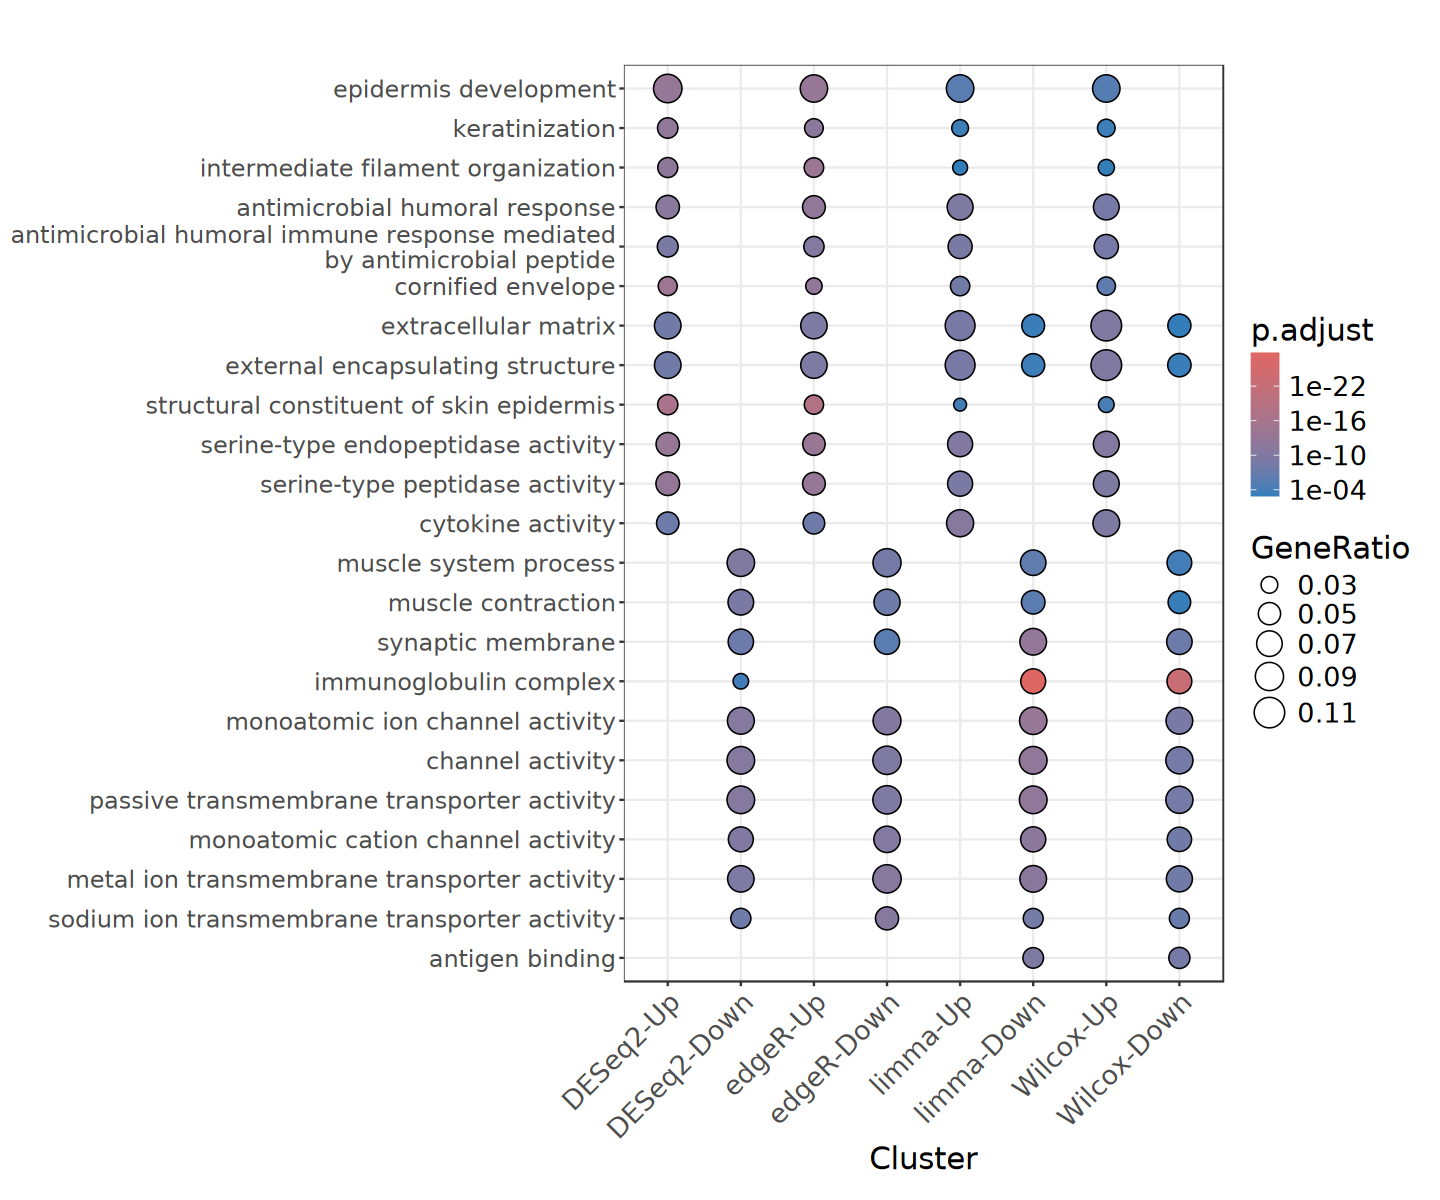

In [63]:
options(repr.plot.width = 12, repr.plot.height = 10)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        # plot.margin = margin(t = 10, r = 10, b = 10, l = 80),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [64]:
genes_list2 <- list(
    "DESeq2-Up" = deseq2_result$ENTREZID[deseq2_result$result %in% c("Up")],
    "DESeq2-Down" = deseq2_result$ENTREZID[deseq2_result$result %in% c("Down")],
    "edgeR-Up" = edger_result$ENTREZID[edger_result$result %in% c("Up")], 
    "edgeR-Down" = edger_result$ENTREZID[edger_result$result %in% c("Down")], 
    "limma-Up" = limma_result$ENTREZID[limma_result$result %in% c("Up")], 
    "limma-Down" = limma_result$ENTREZID[limma_result$result %in% c("Down")], 
    "Wilcox-Up" = wilcox_result$ENTREZID[wilcox_result$result %in% c("Up")], 
    "Wilcox-Down" = wilcox_result$ENTREZID[wilcox_result$result %in% c("Down")])

In [65]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list2, fun = enrichKEGG, 
    universe = rownames(eSet), 
    organism = "hsa", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

Warning message in (function (con = stdin(), n = -1L, ok = TRUE, warn = TRUE, encoding = "unknown", :
“URL 'https://rest.kegg.jp/link/hsa/pathway': Timeout of 60 seconds was reached”


ERROR: Error in (function (con = stdin(), n = -1L, ok = TRUE, warn = TRUE, encoding = "unknown", : cannot read from connection


In [ ]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

In [ ]:
options(repr.plot.width = 12, repr.plot.height = 10)

dotplot(ekegg_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        # plot.margin = margin(t = 10, r = 10, b = 10, l = 80),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

## 3). GSVA

# 8. Immune Infiltration

In [136]:
suppressPackageStartupMessages(library(estimate))
suppressPackageStartupMessages(library(rstatix))
suppressPackageStartupMessages(library(xCell))
suppressPackageStartupMessages(library(MCPcounter))
suppressPackageStartupMessages(library(CIBERSORT))
suppressPackageStartupMessages(library(quantiseqr))
suppressPackageStartupMessages(library(EPIC))
suppressPackageStartupMessages(library(ConsensusTME))
suppressPackageStartupMessages(library(immunedeconv))

ERROR: Error in library(estimate): there is no package called ‘estimate’


# 9. Survival Analysis

In [ ]:
suppressPackageStartupMessages(library(survival))
suppressPackageStartupMessages(library(survminer))
suppressPackageStartupMessages(library(ggsurvfit))
suppressPackageStartupMessages(library(finalfit))

In [67]:
eSet

class: SummarizedExperiment 
dim: 19765 1183 
metadata(0):
assays(1): counts
rownames(19765): A1BG A1CF ... ZZEF1 AC118549.1
rowData names(0):
colnames(1183): CRC.SW.U0001.T CRC.SW.U0002.T ... CRC.SW.UM172.T
  CRC.SW.UM173.T
colData names(9): Patient Sex ... Survival_Status Group

In [ ]:
df <- colData(eSet) |> as.data.frame() |>
    mutate(
        SexId = recode(Sex, Male = 1, Female = 2),
        Event = recode(Vital_Status, Alive = 0, Dead = 1)) |>
    select(Time = Survival_Days, Event, SexId, AJCC_Stage)

head(df)

,Time,Event,SexId,Stage
,<int>,<dbl>,<dbl>,<fct>
CRC.SW.U0001.T,3496,1,2,Stage II
CRC.SW.U0002.T,4858,0,2,Stage III
CRC.SW.U0004.T,4816,0,2,Stage II
CRC.SW.U0005.T,2496,1,2,Stage III
CRC.SW.U0006.T,799,1,1,Stage III
CRC.SW.U0007.T,4690,0,1,Stage III


In [69]:
# edgeR TMM
norm_mat <- cpm(
    dgel, normalized.lib.sizes = TRUE, 
    log = TRUE, prior.count = 1)

In [ ]:
# Creates survival curves using the Kaplan-Meier method
sfit <- survfit(Surv(Time, Event) ~ AJCC_Stage, data = df)
print(sfit)

Call: survfit(formula = Surv(Time, Event) ~ Stage, data = df)

   1 observation deleted due to missingness 
                  n events median 0.95LCL 0.95UCL
Stage=Stage I   158     50   5181    4127      NA
Stage=Stage II  434    190   3769    3329    5124
Stage=Stage III 471    197   4085    3572    5329
Stage=Stage IV  119     96    852     628     973


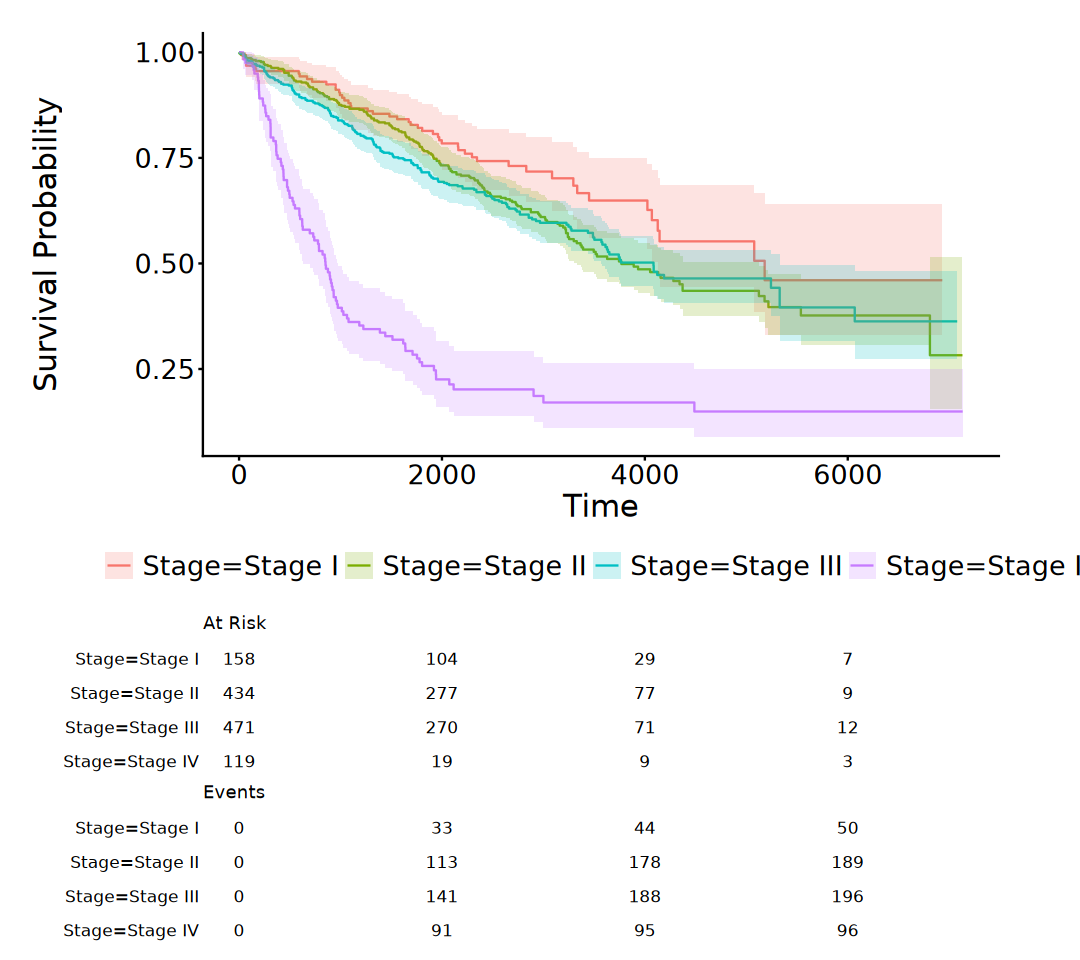

In [109]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggsurvfit::ggsurvfit(sfit) +
    ggsurvfit::add_confidence_interval() +
    ggsurvfit::add_risktable() + 
    theme_classic() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 3, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.position = "bottom",
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

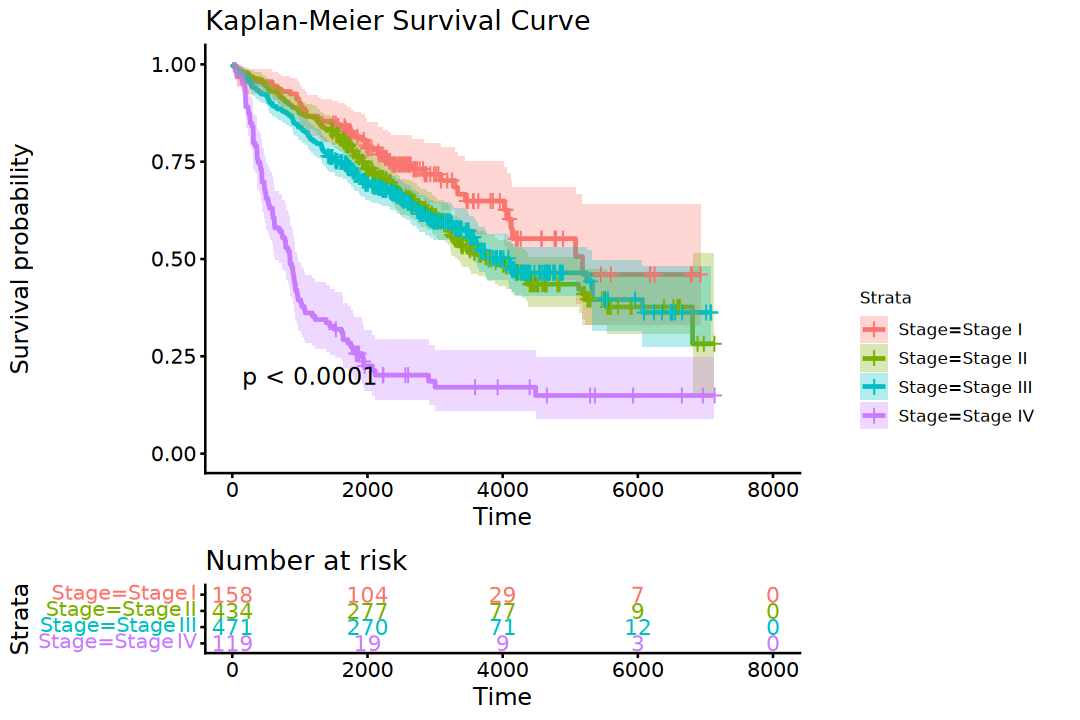

In [103]:
options(repr.plot.width = 9, repr.plot.height = 6)

survminer::ggsurvplot(
    sfit, pval = TRUE, conf.int = TRUE,
    title = "Kaplan-Meier Survival Curve", legend = "right",
    risk.table = TRUE, risk.table.col = "strata")

In [ ]:
logrank_test <- survdiff(Surv(Time, Event) ~ AJCC_Stage, data = df)
print(logrank_test)

Call:
survdiff(formula = Surv(Time, Event) ~ Stage, data = df)

n=1182, 1 observation deleted due to missingness.

                  N Observed Expected (O-E)^2/E (O-E)^2/V
Stage=Stage I   158       50     77.0      9.46     11.07
Stage=Stage II  434      190    213.0      2.48      4.13
Stage=Stage III 471      197    213.5      1.27      2.13
Stage=Stage IV  119       96     29.6    149.32    159.83

 Chisq= 164  on 3 degrees of freedom, p= <2e-16 


In [ ]:
cox_model <- coxph(Surv(Time, Event) ~ AJCC_Stage, data = df)
summary(cox_model)

Call:
coxph(formula = Surv(Time, Event) ~ Stage, data = df)

  n= 1182, number of events= 533 
   (1 observation deleted due to missingness)

                 coef exp(coef) se(coef)     z Pr(>|z|)    
StageStage II  0.3172    1.3733   0.1590 1.995   0.0460 *  
StageStage III 0.3523    1.4224   0.1584 2.225   0.0261 *  
StageStage IV  1.6347    5.1279   0.1755 9.316   <2e-16 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

               exp(coef) exp(-coef) lower .95 upper .95
StageStage II      1.373     0.7282     1.006     1.875
StageStage III     1.422     0.7030     1.043     1.940
StageStage IV      5.128     0.1950     3.636     7.233

Concordance= 0.606  (se = 0.013 )
Likelihood ratio test= 109.7  on 3 df,   p=<2e-16
Wald test            = 142  on 3 df,   p=<2e-16
Score (logrank) test = 164.3  on 3 df,   p=<2e-16


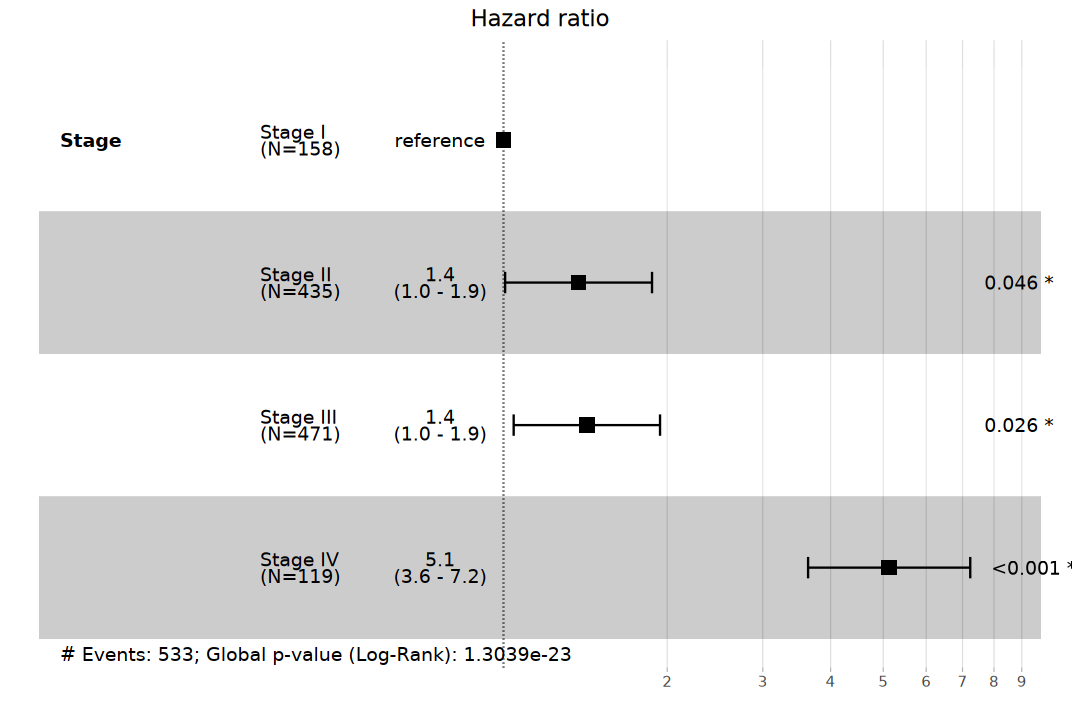

In [104]:
options(repr.plot.width = 9, repr.plot.height = 6)

survminer::ggforest(cox_model, data = df, fontsize = 1)

# 10. Molecular Subtyping

# 11. WGCNA

In [12]:
suppressPackageStartupMessages(library(WGCNA))

In [13]:
norm_mat <- cpm(
    dgel, normalized.lib.sizes = TRUE, 
    log = TRUE, prior.count = 1)

In [14]:
top_idx <- norm_mat[, dgel$samples$Group == "Tumour"] |>
    apply(MARGIN = 1, FUN = mad) |> 
    order(decreasing = T) |> 
    head(n = 5000)

norm_mat <- norm_mat[top_idx, eSet$Group == "Tumour"]

dim(norm_mat)

[1] 5000 1063

In [15]:
gsg <- norm_mat |> t() |> goodSamplesGenes()

 Flagging genes and samples with too many missing values...
  ..step 1


In [ ]:
summary(gsg)
gsg$allOK

            Length Class  Mode   
goodGenes   5000   -none- logical
goodSamples 1063   -none- logical
allOK          1   -none- logical

[1] TRUE

In [17]:
spt <- norm_mat |> t() |> pickSoftThreshold(networkType = "unsigned")

Warning message:
“executing %dopar% sequentially: no parallel backend registered”


   Power SFT.R.sq  slope truncated.R.sq mean.k. median.k. max.k.
1      1    0.117 -0.376          0.721 740.000  6.76e+02 1550.0
2      2    0.764 -1.150          0.853 209.000  1.42e+02  773.0
3      3    0.816 -1.290          0.886  83.800  3.81e+01  466.0
4      4    0.837 -1.310          0.913  41.100  1.17e+01  309.0
5      5    0.861 -1.290          0.954  22.900  4.03e+00  219.0
6      6    0.871 -1.290          0.967  13.900  1.50e+00  163.0
7      7    0.873 -1.320          0.977   9.010  6.18e-01  126.0
8      8    0.877 -1.340          0.983   6.100  2.73e-01   99.9
9      9    0.885 -1.350          0.987   4.290  1.24e-01   80.7
10    10    0.882 -1.380          0.985   3.110  5.85e-02   66.2
11    12    0.899 -1.390          0.992   1.750  1.40e-02   46.1
12    14    0.905 -1.400          0.991   1.050  3.42e-03   33.2
13    16    0.918 -1.400          0.991   0.673  9.31e-04   24.6
14    18    0.924 -1.370          0.992   0.448  2.54e-04   18.5
15    20    0.932 -1.350 

In [18]:
p1 <- ggplot(spt$fitIndices) +
    geom_point(aes(x = Power, y = SFT.R.sq)) + 
    geom_hline(yintercept = 0.8, color = "red") +
    labs(
        title = "Scale independence", x = "Soft Threshold (power)",
        y = "Scale Free Topology Model Fit,signed R^2") +
    theme_classic() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

p2 <- ggplot(spt$fitIndices) +
    geom_point(aes(x = Power, y = mean.k.)) + 
    labs(
        title = "Mean connectivity", 
        x = "Soft Threshold (power)", y = "Mean Connectivity") +
    theme_classic() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

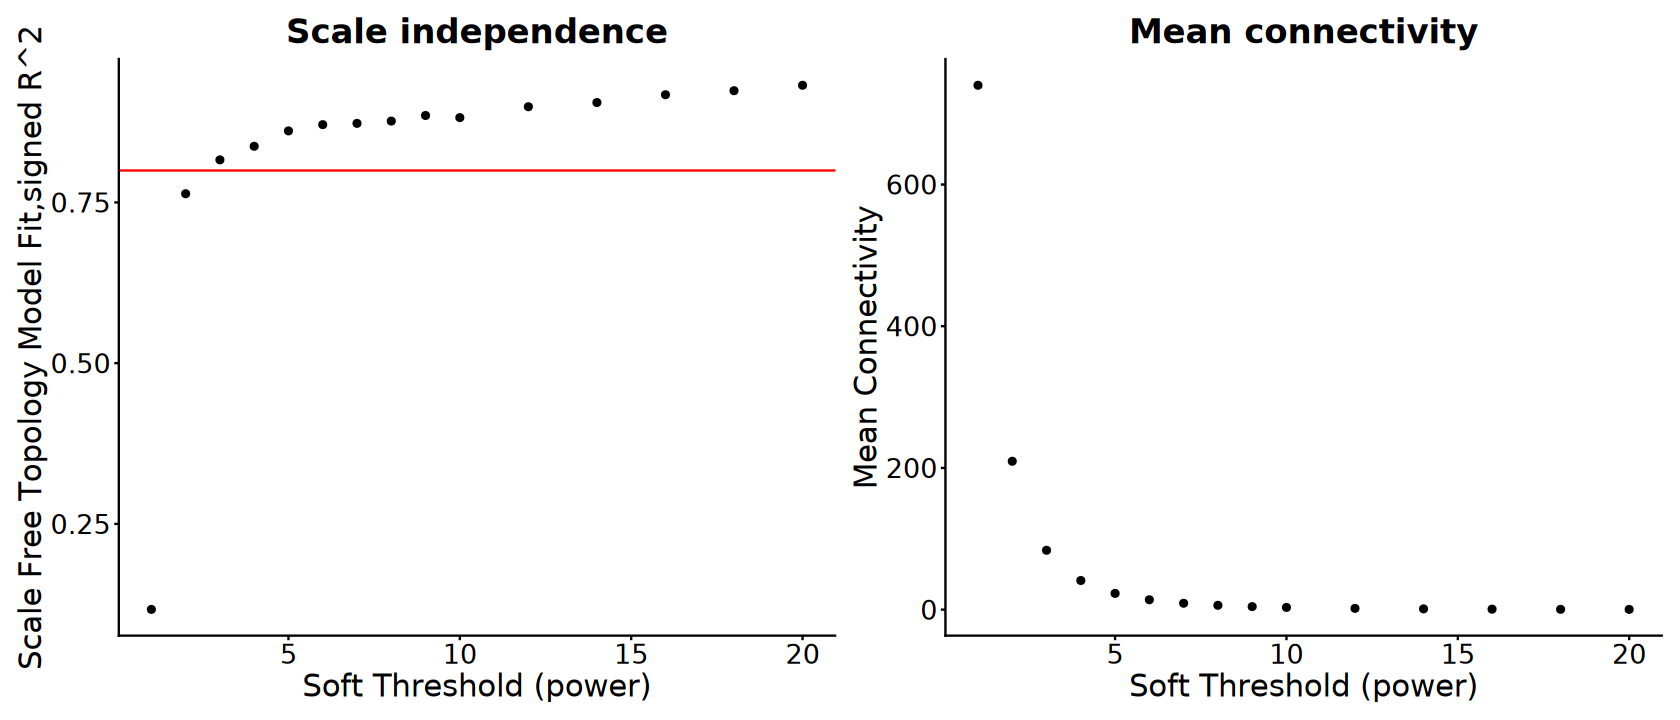

In [19]:
options(repr.plot.width = 14, repr.plot.height = 6)
p1 + p2

In [119]:
adjacency <- norm_mat |> t() |> adjacency(power = spt$powerEstimate)

adjacency[1:6, 1:6]

,RPS4Y1,EIF1AY,USP9Y,ZIC5,UTY,ZFY
RPS4Y1,1.0000000000,8.296238e-01,0.838549452,1.006178e-04,0.8620672775,8.735432e-01
EIF1AY,0.8296238101,1.000000e+00,0.873740485,5.879994e-05,0.9064643107,9.108597e-01
USP9Y,0.8385494518,8.737405e-01,1.000000000,1.114040e-04,0.9089456895,8.993701e-01
ZIC5,0.0001006178,5.879994e-05,0.000111404,1.000000e+00,0.0001507655,9.419815e-05
UTY,0.8620672775,9.064643e-01,0.908945690,1.507655e-04,1.0000000000,9.344576e-01
ZFY,0.8735432076,9.108597e-01,0.899370137,9.419815e-05,0.9344575596,1.000000e+00


In [120]:
TOM <- TOMsimilarity(adjacency)
TOM[1:6, 1:6]

..connectivity..
..matrix multiplication (system BLAS)..
..normalization..
..done.


1.0000000000,0.8642663408,0.8770703587,0.0001560442,0.8945152500,0.8948374882
0.8642663408,1.0000000000,0.8788854810,0.0001546845,0.8965828711,0.8966099573
0.8770703587,0.8788854810,1.0000000000,0.0001752949,0.8936647162,0.8936542326
0.0001560442,0.0001546845,0.0001752949,1.0000000000,0.0001868459,0.0001699522
0.8945152500,0.8965828711,0.8936647162,0.0001868459,1.0000000000,0.8953895578
0.8948374882,0.8966099573,0.8936542326,0.0001699522,0.8953895578,1.0000000000


In [121]:
TOM.dissimilarity <- 1 - TOM
TOM.dissimilarity[1:6, 1:6]

0.0000000,0.1357337,0.1229296,0.9998440,0.1054848,0.1051625
0.1357337,0.0000000,0.1211145,0.9998453,0.1034171,0.1033900
0.1229296,0.1211145,0.0000000,0.9998247,0.1063353,0.1063458
0.9998440,0.9998453,0.9998247,0.0000000,0.9998132,0.9998300
0.1054848,0.1034171,0.1063353,0.9998132,0.0000000,0.1046104
0.1051625,0.1033900,0.1063458,0.9998300,0.1046104,0.0000000


In [122]:
geneTree <- hclust(as.dist(TOM.dissimilarity), method = "average")

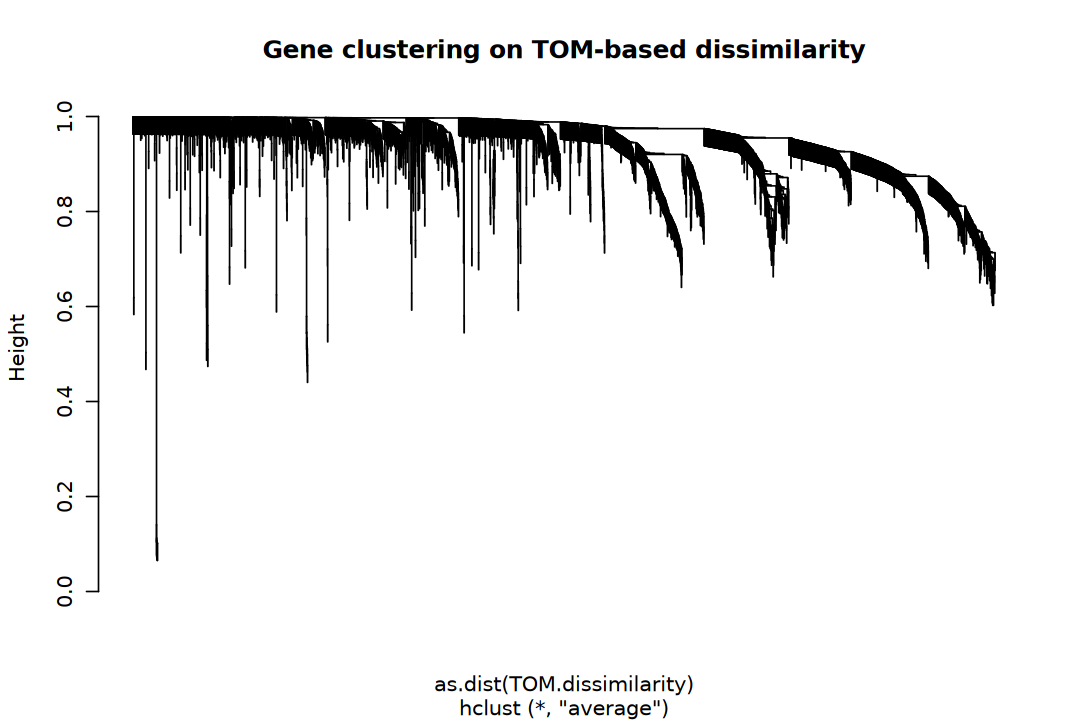

In [123]:
options(repr.plot.width = 9, repr.plot.height = 6)

plot(
    geneTree, main = "Gene clustering on TOM-based dissimilarity", 
    labels = FALSE, hang = 0.04)

In [124]:
Modules <- cutreeDynamic(
    dendro = geneTree, distM = TOM.dissimilarity, deepSplit = 2, 
    pamRespectsDendro = FALSE, minClusterSize = 30)

table(Modules)

 ..cutHeight not given, setting it to 0.998  ===>  99% of the (truncated) height range in dendro.
 ..done.


Modules
   0    1    2    3    4    5    6    7    8    9   10   11 
 666 1620  668  455  347  299  227  176  171  150  126   95 

In [125]:
ModuleColors <- labels2colors(Modules)
table(ModuleColors)

ModuleColors
      black        blue       brown       green greenyellow        grey 
        176         668         455         299          95         666 
    magenta        pink      purple         red   turquoise      yellow 
        150         171         126         227        1620         347 

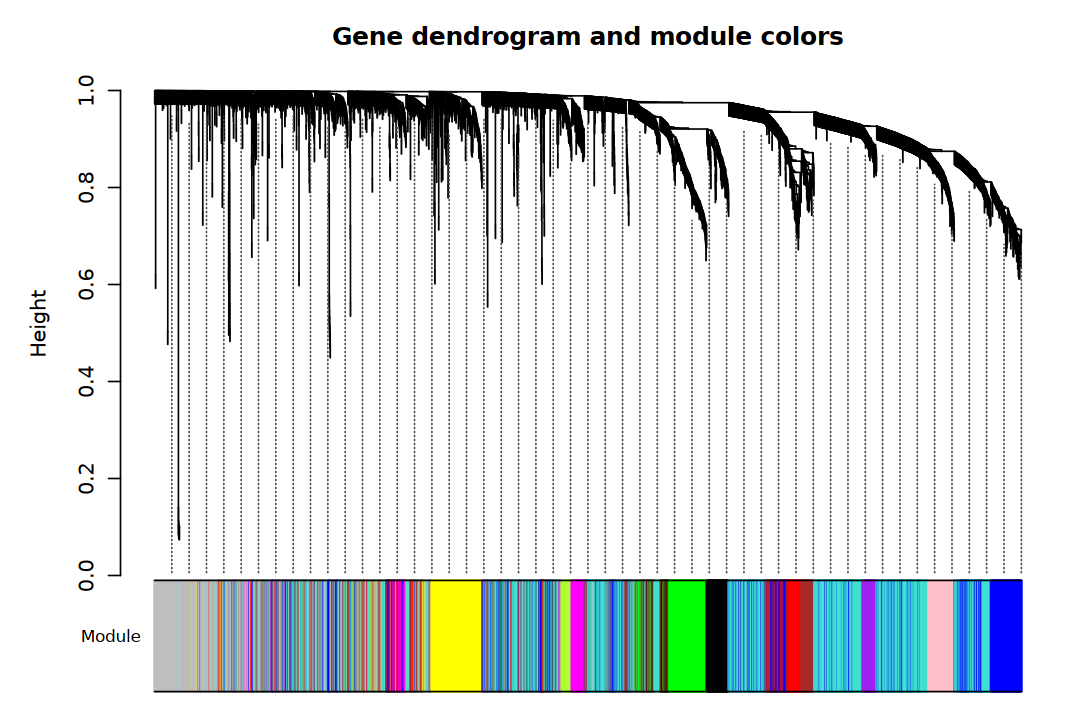

In [126]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotDendroAndColors(
    geneTree, ModuleColors,"Module", dendroLabels = FALSE, 
    hang = 0.03, addGuide = TRUE, guideHang = 0.05,
    main = "Gene dendrogram and module colors")

In [129]:
MElist <- norm_mat |> t() |> moduleEigengenes(colors = ModuleColors) 
MEs <- MElist$eigengenes

MEs[1:6, 1:6]

,MEblack,MEblue,MEbrown,MEgreen,MEgreenyellow,MEgrey
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
CRC.SW.U0001.T,-0.007746701,0.021668622,-0.001307526,-0.002975180,0.034217115,-0.029969324
CRC.SW.U0002.T,0.005812330,0.012288201,-0.001794270,0.004308186,0.021834323,0.019093223
CRC.SW.U0004.T,-0.012109140,0.003411221,-0.021948039,-0.018548916,0.007326188,0.004026768
CRC.SW.U0005.T,-0.029961671,0.027155008,-0.020677057,-0.018720018,0.006828177,-0.002952412
CRC.SW.U0006.T,-0.041880260,0.004345888,-0.024208640,-0.050001365,-0.021883090,0.011631979
CRC.SW.U0007.T,-0.014510640,-0.007492585,-0.019534354,-0.023241453,0.029454730,0.023481048


In [130]:
ME.dissimilarity = 1 - cor(MElist$eigengenes, use = "complete")

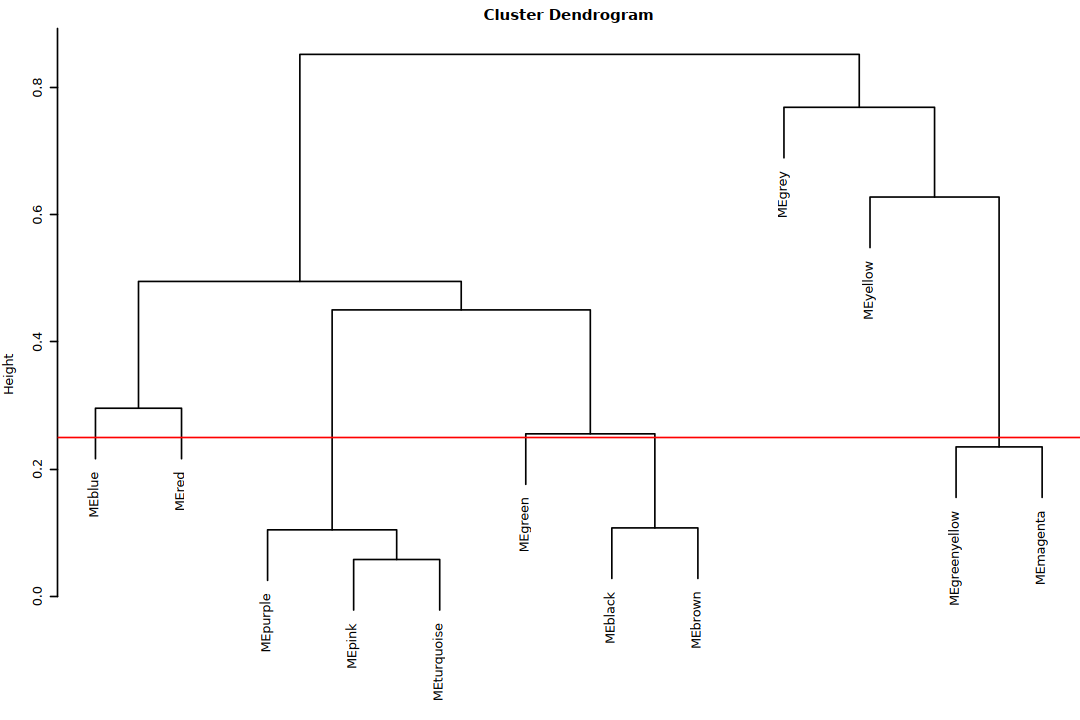

In [131]:
METree = hclust(as.dist(ME.dissimilarity), method = "average")

par(mar = c(0,4,2,0))
par(cex = 0.6)
plot(METree)
abline(h=.25, col = "red")

In [132]:
merge <- norm_mat |> t() |> mergeCloseModules(ModuleColors, cutHeight = .25)

 mergeCloseModules: Merging modules whose distance is less than 0.25
   Calculating new MEs...


In [133]:
# The merged module colors, assigning one color to each module
mergedColors = merge$colors
# Eigengenes of the new merged modules
mergedMEs = merge$newMEs

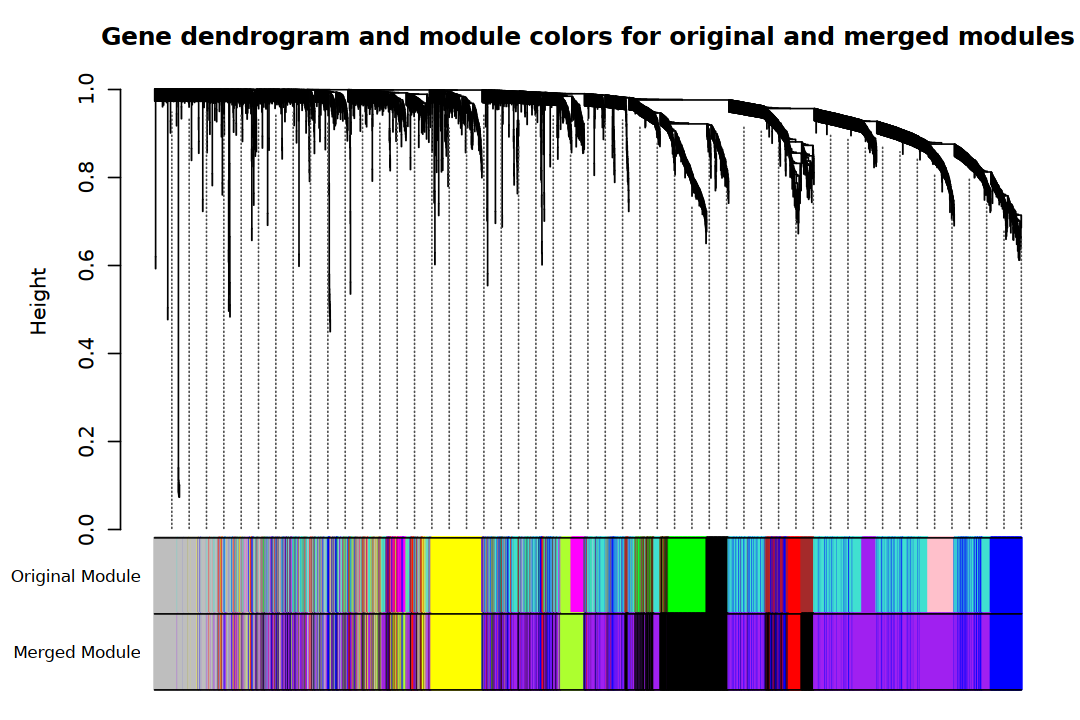

In [134]:
options(repr.plot.width = 9, repr.plot.height = 6)

plotDendroAndColors(
    geneTree, cbind(ModuleColors, mergedColors), 
    c("Original Module", "Merged Module"),
    dendroLabels = FALSE, hang = 0.03, addGuide = TRUE, guideHang = 0.05,
    main = "Gene dendrogram and module colors for original and merged modules")

In [135]:
MEs_col <- MEs
colnames(MEs_col) <- paste0(
    "ME", labels2colors(as.numeric(str_replace_all(colnames(MEs_col),"ME",""))))
MEs_col <- orderMEs(MEs_col)

plotEigengeneNetworks(
    MEs_col, "Eigengene adjacency heatmap",
    marDendro = c(3, 3, 2, 4), marHeatmap = c(3, 4, 2, 2),
    plotDendrograms = TRUE, xLabelsAngle = 90)

Warning message in labels2colors(as.numeric(str_replace_all(colnames(MEs_col), "ME", :
“NAs introduced by coercion”
Warning message in max(nLabels, na.rm = TRUE):
“no non-missing arguments to max; returning -Inf”


ERROR: Error in orderMEs(MEs_col): orderMEs: given MEs and order have incompatible dimensions.


In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)
TOMplot(plotTOM, net$dendrograms[[1]], 
        moduleColors[net$blockGenes[[1]]],
        main = "Network heatmap plot, all genes",
        col = gplots::colorpanel(250, 'red', "orange", 'lemonchiffon'))

In [ ]:
# Isolate weight from the clinical traits
weight = as.data.frame(datTraits$weight_g);
names(weight) = "weight"
# Add the weight to existing module eigengenes
MET = orderMEs(cbind(MEs, weight))
# Plot the relationships among the eigengenes and the trait
par(cex = 0.9)
plotEigengeneNetworks(MET, "", marDendro = c(0,4,1,2), marHeatmap = c(5,4,1,2), cex.lab = 0.8, xLabelsAngle
= 90)

# 12. Predictive Mode

# 13. Biomarker Discovery

# Reference

> 1. [Survival analysis in R](https://www.emilyzabor.com/survival-analysis-in-r.html)